In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier

warnings.filterwarnings("ignore")

# 1 LOAD DATA

In [4]:
CSV_PATH = "social_media_comments.csv"  

def load_csv_safely(path: str) -> pd.DataFrame:
    encodings = ["utf-8", "utf-8-sig", "cp1254", "latin1", "iso-8859-9", "utf-16"]
    seps = [",", ";", "\t", "|"]
    last_err = None

    for enc in encodings:
        for sep in seps:
            try:
                df = pd.read_csv(path, encoding=enc, sep=sep)
                if df.shape[1] == 1 and sep != ",":
                    continue
                print(f"[OK] Loaded CSV with encoding='{enc}', sep='{sep}' | shape={df.shape}")
                return df
            except Exception as e:
                last_err = e

    raise RuntimeError(f"Could not read CSV. Last error: {last_err}")

df = load_csv_safely(CSV_PATH)

df = df.rename(columns={"Paylaþým": "Paylaşım"})

[OK] Loaded CSV with encoding='cp1254', sep=',' | shape=(11119, 2)


# 2 FIND COLUMNS

In [5]:
# Try to detect the text column
candidate_text_cols = ["Paylaşım", "Paylasim", "text", "yorum", "comment", "review"]
TEXT_COL = next((c for c in candidate_text_cols if c in df.columns), None)

if TEXT_COL is None:
    obj_cols = [c for c in df.columns if df[c].dtype == "object"]
    if not obj_cols:
        raise ValueError("No text-like column found. Please set TEXT_COL manually.")
    # pick the object column with highest average string length
    TEXT_COL = max(obj_cols, key=lambda c: df[c].astype(str).str.len().mean())

# Optional sentiment label column if it exists (your file likely has "Tip")
LABEL_COL = "Tip" if "Tip" in df.columns else None

print(f"[INFO] Using TEXT_COL='{TEXT_COL}'")
print(f"[INFO] Using LABEL_COL='{LABEL_COL}' (None means not found)")


[INFO] Using TEXT_COL='Paylaşım'
[INFO] Using LABEL_COL='Tip' (None means not found)


# 3 PREPROCESS TEXT

In [6]:
URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#\w+")
MULTISPACE_RE = re.compile(r"\s+")

def normalize_tr(text: str) -> str:
    """Turkish-friendly normalization for TF-IDF + lexicon matching."""
    if pd.isna(text):
        return ""
    t = str(text).lower()
    t = URL_RE.sub(" ", t)
    t = MENTION_RE.sub(" ", t)
    t = HASHTAG_RE.sub(" ", t)
    # preserve Turkish letters
    t = re.sub(r"[^a-zçğıöşü0-9\s]", " ", t)
    t = MULTISPACE_RE.sub(" ", t).strip()
    return t

df["text_norm"] = df[TEXT_COL].apply(normalize_tr)



# 4 EMOTION LEXICON (PSEUDO-LABELS)

In [7]:
# NOTE: Expand this lexicon to improve accuracy.
EMOTION_LEXICON = {
    "anger": [
        "sinir", "öfke", "kızgın", "delir", "çıldır", "lan",
        "namussuz", "şerefsiz", "aptal", "salak", "gerizekalı",
        "kahpe", "sikeyim", "s*keyim", "sokayım", "küfür", "nefret", "hakaret"
    ],
    "joy": [
        "mutlu", "sevin", "sevindim", "güzel", "harika", "mükemmel",
        "süper", "tebrik", "bayıldım", "keyif", "neşe", "sevg", "aşk", "şahane", "iyi"
    ],
    "sadness": [
        "üzgün", "üzüldüm", "keder", "acı", "ağla", "ağlıyorum",
        "hüzün", "yas", "kahroldum", "yıkıldım"
    ],
    "fear": ["kork", "korku", "endişe", "panik", "dehşet", "tedirgin", "ürk", "kaygı"],
    "disgust": ["iğren", "iğrenç", "tiksin", "pis", "rezil", "berbat", "mide", "kus", "tiksinti"],
}

LEX_PAT = {
    emo: re.compile(r"\b(" + "|".join(map(re.escape, terms)) + r")\b", re.IGNORECASE)
    for emo, terms in EMOTION_LEXICON.items()
}
def detect_emotion(text_norm: str) -> str:
    """Return one dominant emotion label; 'neutral' if nothing matches."""
    if not text_norm:
        return "neutral"

    scores = {}
    for emo, pat in LEX_PAT.items():
        scores[emo] = len(pat.findall(text_norm))

    best_score = max(scores.values()) if scores else 0
    if best_score == 0:
        return "neutral"

    # tie-break order (deterministic)
    order = ["anger", "disgust", "fear", "sadness", "joy"]
    best = sorted(scores.items(), key=lambda kv: (-kv[1], order.index(kv[0]) if kv[0] in order else 999))[0][0]
    return best

df["emotion"] = df["text_norm"].apply(detect_emotion)

# 5 EDA (STATISTICS)

In [8]:
df["char_len"] = df[TEXT_COL].astype(str).str.len()
df["word_count"] = df["text_norm"].astype(str).str.split().apply(len)

print("\n=== BASIC DATASET INFO ===")
print("Rows:", len(df))
print("Columns:", list(df.columns))

print("\n=== LENGTH STATS (char_len, word_count) ===")
print(df[["char_len", "word_count"]].describe().round(2))

print("\n=== EMOTION COUNTS ===")
print(df["emotion"].value_counts())

if LABEL_COL:
    print("\n=== SENTIMENT COUNTS ===")
    print(df[LABEL_COL].value_counts())

    print("\n=== SENTIMENT x EMOTION CROSSTAB ===")
    print(pd.crosstab(df[LABEL_COL], df["emotion"]))


=== BASIC DATASET INFO ===
Rows: 11119
Columns: ['Tip', 'Paylaşım', 'text_norm', 'emotion', 'char_len', 'word_count']

=== LENGTH STATS (char_len, word_count) ===
       char_len  word_count
count  11119.00    11119.00
mean      73.66       10.08
std       54.28        7.31
min        3.00        0.00
25%       34.00        5.00
50%       60.00        8.00
75%       97.00       13.00
max      476.00       61.00

=== EMOTION COUNTS ===
emotion
neutral    9515
anger       938
joy         543
disgust      69
sadness      46
fear          8
Name: count, dtype: int64

=== SENTIMENT COUNTS ===
Tip
Pozitif    6115
Negatif    5004
Name: count, dtype: int64

=== SENTIMENT x EMOTION CROSSTAB ===
emotion  anger  disgust  fear  joy  neutral  sadness
Tip                                                 
Negatif    750       55     0  124     4063       12
Pozitif    188       14     8  419     5452       34


# 6 VISUALIZATIONS (EDA)

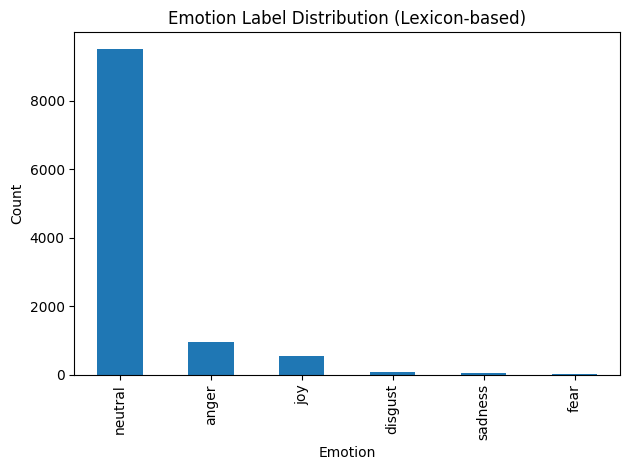

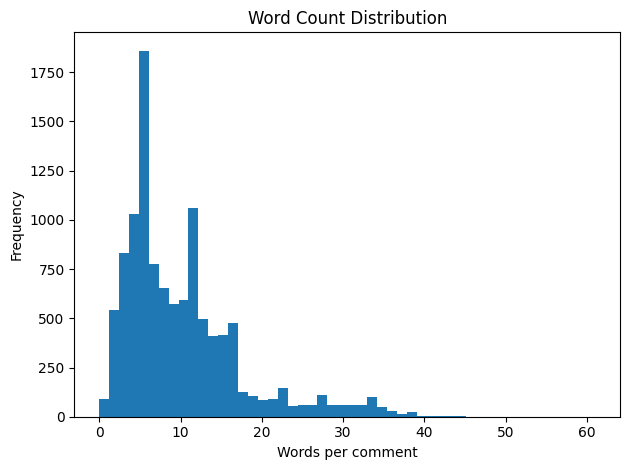

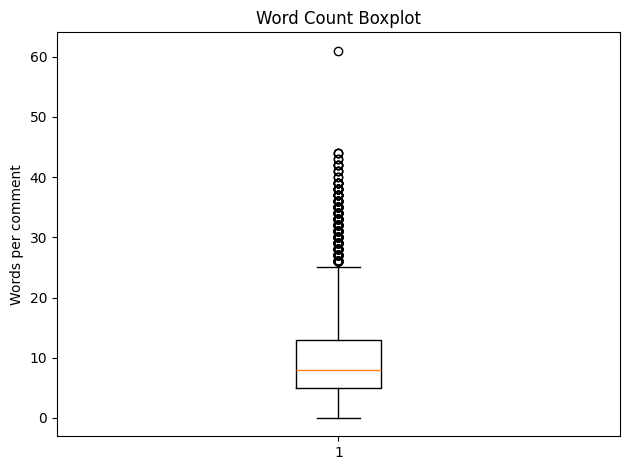

In [9]:
plt.figure()
df["emotion"].value_counts().plot(kind="bar")
plt.title("Emotion Label Distribution (Lexicon-based)")
plt.xlabel("Emotion")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 6.2 Word count histogram
plt.figure()
plt.hist(df["word_count"], bins=50)
plt.title("Word Count Distribution")
plt.xlabel("Words per comment")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 6.3 Word count boxplot
plt.figure()
plt.boxplot(df["word_count"], vert=True)
plt.title("Word Count Boxplot")
plt.ylabel("Words per comment")
plt.tight_layout()
plt.show()


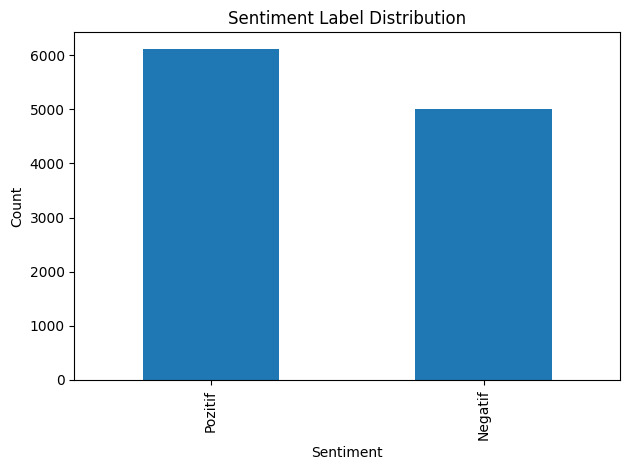

In [10]:
if LABEL_COL:
    plt.figure()
    df[LABEL_COL].value_counts().plot(kind="bar")
    plt.title("Sentiment Label Distribution")
    plt.xlabel("Sentiment")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# 7 MODEL TRAINING + COMPARISON


=== Dummy (most_frequent) ===
Accuracy: 0.8557 | Macro-F1: 0.1537 | Weighted-F1: 0.7891
              precision    recall  f1-score   support

       anger     0.0000    0.0000    0.0000       188
     disgust     0.0000    0.0000    0.0000        14
        fear     0.0000    0.0000    0.0000         1
         joy     0.0000    0.0000    0.0000       109
     neutral     0.8557    1.0000    0.9222      1903
     sadness     0.0000    0.0000    0.0000         9

    accuracy                         0.8557      2224
   macro avg     0.1426    0.1667    0.1537      2224
weighted avg     0.7322    0.8557    0.7891      2224


=== LogReg (multinomial) ===
Accuracy: 0.9879 | Macro-F1: 0.7403 | Weighted-F1: 0.9872
              precision    recall  f1-score   support

       anger     1.0000    0.9202    0.9584       188
     disgust     0.9167    0.7857    0.8462        14
        fear     0.0000    0.0000    0.0000         1
         joy     0.9906    0.9633    0.9767       109
     neut

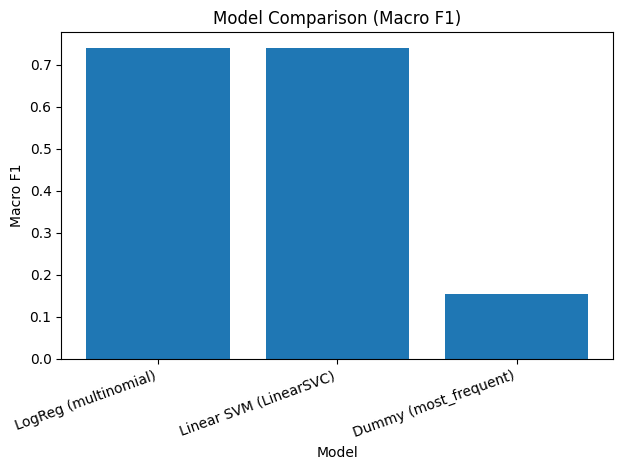

<Figure size 700x600 with 0 Axes>

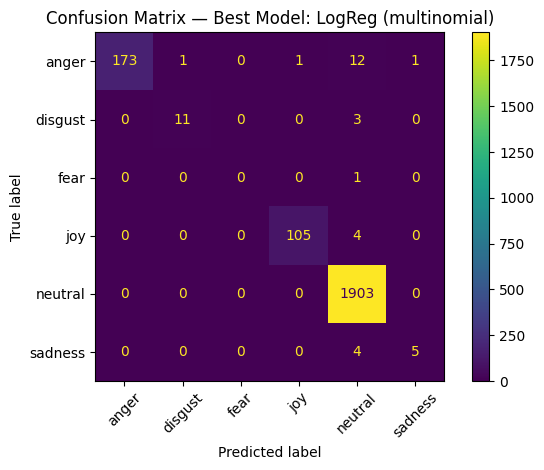

In [11]:
X = df["text_norm"].astype(str).values
y = df["emotion"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tfidf_params = dict(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True
)
models = {
    "Dummy (most_frequent)": Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_params)),
        ("clf", DummyClassifier(strategy="most_frequent"))
    ]),
    "LogReg (multinomial)": Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_params)),
        ("clf", LogisticRegression(
            solver="lbfgs",
            multi_class="multinomial",
            class_weight="balanced",
            C=2.0,
            max_iter=2000
        ))
    ]),
    "Linear SVM (LinearSVC)": Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_params)),
        ("clf", LinearSVC(C=1.0, class_weight="balanced"))
    ])
}
labels_sorted = sorted(np.unique(y))
rows = []
all_reports = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    acc = accuracy_score(y_test, pred)
    f1m = f1_score(y_test, pred, average="macro")
    f1w = f1_score(y_test, pred, average="weighted")

    rows.append((name, acc, f1m, f1w))
    all_reports[name] = classification_report(y_test, pred, digits=4, zero_division=0)

    print(f"\n=== {name} ===")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {f1m:.4f} | Weighted-F1: {f1w:.4f}")
    print(all_reports[name])
    results_df = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro F1", "Weighted F1"])\
               .sort_values("Macro F1", ascending=False)\
               .reset_index(drop=True)

print("\n=== MODEL COMPARISON TABLE ===")
print(results_df)

# 7.1 Plot model comparison (Macro F1)
plt.figure()
plt.bar(results_df["Model"], results_df["Macro F1"])
plt.title("Model Comparison (Macro F1)")
plt.xlabel("Model")
plt.ylabel("Macro F1")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
# 7.2 Confusion matrix for best model
best_model_name = results_df.iloc[0]["Model"]
best_pipe = models[best_model_name]
best_pred = best_pipe.predict(X_test)
cm = confusion_matrix(y_test, best_pred, labels=labels_sorted)

plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_sorted)
disp.plot(xticks_rotation=45, values_format="d")
plt.title(f"Confusion Matrix — Best Model: {best_model_name}")
plt.tight_layout()
plt.show()